# Guided Year-End Chart — Billboard Hot 100, 2000–2024
_Where songs sat on the year-end list, and what genre and audio features do with that rank_

***

**Programming Language:** Python in the Jupyter Notebook Environment

**Dataset:** [matthewwilliams333/billboard-hot-100-year-end-tracks-2000-2024](https://www.kaggle.com/datasets/matthewwilliams333/billboard-hot-100-year-end-tracks-2000-2024)

**Style counterpart:** [Guided Numeric and Text Exploration — E-Commerce](https://www.kaggle.com/code/nicapotato/guided-numeric-and-text-exploration-e-commerce)

**Code Navigation:** <br>
In the code, text after hashtags (`#`) are supportive explanations, not executed as code.

***

# Tables of Content:

**1. [Introduction](#Introduction)** <br>
**2. [Setup and Data Peek](#Setup)** <br>
**3. [Univariate Distributions](#Univariate)** <br>
**4. [Genre and Explicitness](#Genre)** <br>
**5. [Audio, Words, and Rank](#Audio)** <br>
**6. [What Lines Up with Year-End Rank](#Model)** <br>
**7. [What It Means — Working Synthesis](#Synthesis)** <br>

# **1. Introduction:** <a id="Introduction"></a> <br>
A chart row is one year-end slot: year, rank, title, and artist. Rank 1 is the top of that year. The file has 2,484 slots across 2000–2024, sixteen short of a full 100-per-year list. Thirteen years have 98 or 99 ranks, and those missing slots stay missing. The 2,484 slots cover 2,246 distinct title–artist pairs; 231 songs return in a later year.

Audio features are blank on 320 tracks and stay blank. Broad genre and the explicit flag are blank on 132 tracks and stay blank. Emotion counts and a primary lyric topic join on title and artist. The n-gram table (`track_word_counts.csv`) stays unloaded; this notebook stays at track and chart-slot grain.

The question is whether genre, explicitness, audio features, or lyric topic separate a better year-end rank from a worse one, and how the chart mix moved from 2000 to 2024. A lower rank number is a higher position.

# **2. Setup and Data Peek:** <a id="Setup"></a>

In [1]:
# General
import numpy as np
import pandas as pd
from pathlib import Path

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

# Scientific / modeling helpers
from IPython.display import display
from scipy import stats
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder

import kagglehub

# Set Plot Theme (same family as the guided series)
sns.set_theme(style="whitegrid")
PALETTE = ["#30a2da", "#fc4f30", "#e5ae38", "#6d904f", "#8b8b8b"]
sns.set_palette(PALETTE)
plt.rcParams["figure.figsize"] = (11, 5)

# Warnings
import warnings
warnings.filterwarnings("ignore")

# Wide table inspection in Jupyter cell outputs
pd.set_option("display.max_columns", 999)
pd.set_option("display.width", 220)


def park_legend(ax, title=""):
    ax.legend(
        title=title,
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
        borderaxespad=0,
        frameon=False,
    )

/Users/nicapotato/Documents/repo/project/KaggleNotebooks/eda/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


**Code Explanation and Reasoning:** <br>
These packages fall into three buckets: *General*, *Visualization*, and *Scientific / modeling helpers*.

`pandas` / `numpy` hold the table; `matplotlib` / `seaborn` do the graphics; `scipy` ranks associations; `sklearn` fits one linear model on a hold-out split (`random_state=7`). `kagglehub` resolves the file both on Kaggle (`/kaggle/input/...`) and locally.

The five-color palette matches the guided series so sequential plots feel like one exploration. When a plot has a legend, `park_legend` places it to the right of the axes.

In [2]:
KAGGLE_SLUG = "matthewwilliams333/billboard-hot-100-year-end-tracks-2000-2024"


def resolve_dir(slug: str = KAGGLE_SLUG) -> Path:
    kaggle_root = Path("/kaggle/input")
    if kaggle_root.exists():
        for p in kaggle_root.rglob("chart_entries.csv"):
            return p.parent
    local = Path("data")
    if (local / "chart_entries.csv").exists():
        return local
    path = Path(kagglehub.dataset_download(slug))
    assert (path / "chart_entries.csv").exists(), f"expected chart_entries.csv under {path}"
    return path


data_dir = resolve_dir()
chart = pd.read_csv(data_dir / "chart_entries.csv")
tracks = pd.read_csv(data_dir / "tracks.csv")
emotions = pd.read_csv(data_dir / "track_emotions.csv")
topics = pd.read_csv(data_dir / "track_topics.csv")
print("Directory:", data_dir)
print("chart_entries:", chart.shape)
print("tracks:", tracks.shape)
print("track_emotions:", emotions.shape)
print("track_topics:", topics.shape)
print("track_word_counts.csv is the n-gram table and is left unloaded.")
assert chart.shape[0] == 2484
assert tracks.shape[0] == 2246
assert chart.duplicated(["year", "rank"]).sum() == 0
assert chart.year.min() == 2000 and chart.year.max() == 2024
per_year = chart.groupby("year").size()
print("Slots short of 100:")
print((100 - per_year).loc[lambda s: s > 0].to_string())
assert int((100 - per_year).sum()) == 16

slot = chart.merge(tracks, on=["title", "artist_name"], how="left", indicator=True)
assert (slot._merge == "both").all()
slot = slot.drop(columns="_merge")
assert len(slot) == 2484
repeat = chart.groupby(["title", "artist_name"]).size()
print("Songs on more than one year-end chart:", int((repeat > 1).sum()))
print("Audio-feature blanks on chart slots:", int(slot.danceability.isna().sum()))
print("Audio-feature blanks on tracks:", int(tracks.danceability.isna().sum()))
print("Genre blanks on tracks:", int(tracks.broad_genre.isna().sum()))
display(chart.sample(5, random_state=7))
print(tracks.dtypes.to_string())

chart_entries: (2484, 4)
tracks: (2246, 22)
track_emotions: (2246, 12)
track_topics: (22451, 8)
track_word_counts.csv is the n-gram table and is left unloaded.
Slots short of 100:
year
2001    2
2002    1
2003    1
2004    2
2007    1
2008    1
2009    1
2010    1
2014    1
2015    2
2017    1
2018    1
2020    1
Songs on more than one year-end chart: 231
Audio-feature blanks on chart slots: 351
Audio-feature blanks on tracks: 320
Genre blanks on tracks: 132


,year,rank,title,artist_name
1684,2016,98,Tiimmy Turner,Desiigner
1744,2017,59,Now or Never,Halsey
2393,2024,10,Too Sweet,Hozier
278,2002,82,The Good Stuff,Kenny Chesney
1661,2016,75,Antidote,Travis Scott


title                      str
artist_name                str
genre                      str
broad_genre                str
is_explicit             object
danceability           float64
energy                 float64
speechiness            float64
acousticness           float64
instrumentalness       float64
liveness               float64
valence                float64
loudness               float64
tempo                  float64
key                    float64
mode                   float64
time_signature         float64
duration_ms            float64
word_count               int64
unique_word_count        int64
lexical_diversity      float64
average_word_length    float64


**Code Explanation and Reasoning:** <br>
The directory resolver finds `chart_entries.csv` under `/kaggle/input`, then under `data/`, then via `kagglehub`. Every chart slot matches a track on title and artist. A song that charts in two years is two slots and one track, so rank questions use the slot table and feature distributions use the track table. Blank audio, genre, and explicitness stay blank.

# **3. Univariate Distributions:** <a id="Univariate"></a>

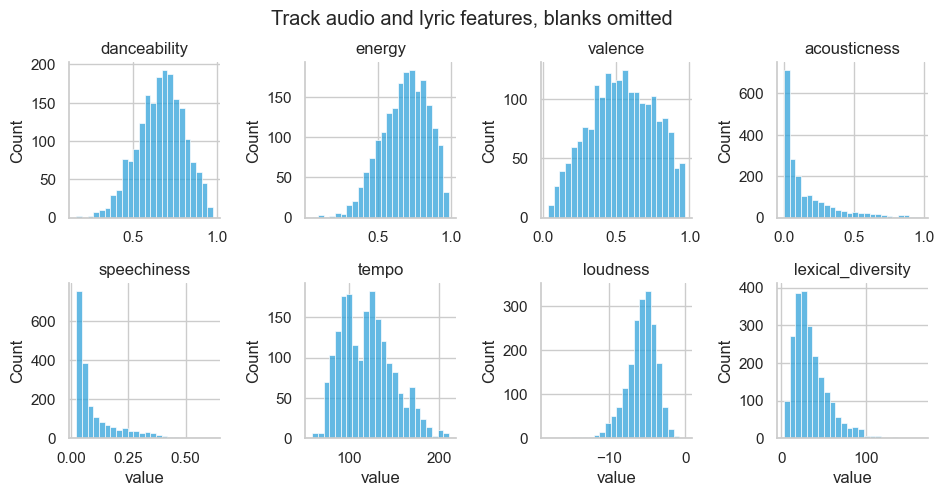

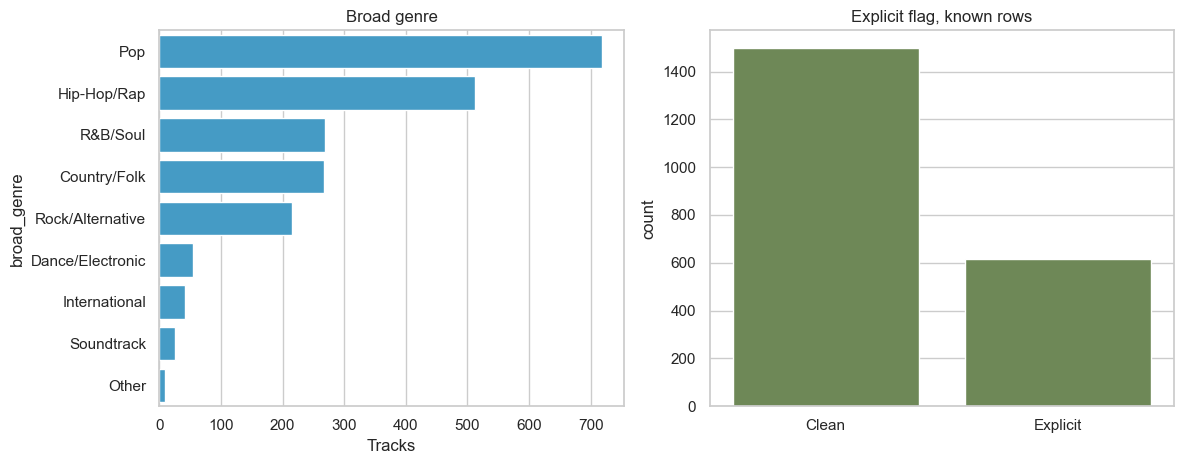

broad_genre
Pop                 718
Hip-Hop/Rap         512
R&B/Soul            269
Country/Folk        268
Rock/Alternative    216
Dance/Electronic     55
International        41
Soundtrack           26
Other                 9
Explicit flag blank on tracks: 132


In [3]:
audio_cols = [
    "danceability", "energy", "valence", "acousticness",
    "speechiness", "tempo", "loudness", "lexical_diversity",
]
long = tracks.melt(value_vars=audio_cols, var_name="feature", value_name="value").dropna()
g = sns.FacetGrid(long, col="feature", col_wrap=4, sharex=False, sharey=False, height=2.4)
g.map_dataframe(sns.histplot, x="value", bins=24, color=PALETTE[0])
g.set_titles("{col_name}")
g.fig.suptitle("Track audio and lyric features, blanks omitted", y=1.03)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
genre_counts = tracks.broad_genre.value_counts(dropna=True)
sns.barplot(x=genre_counts.values, y=genre_counts.index, ax=axes[0], color=PALETTE[0])
axes[0].set_xlabel("Tracks")
axes[0].set_title("Broad genre")
explicit = tracks.is_explicit.map({True: "Explicit", False: "Clean"}).dropna()
sns.countplot(x=explicit, ax=axes[1], color=PALETTE[3], order=["Clean", "Explicit"])
axes[1].set_xlabel("")
axes[1].set_title("Explicit flag, known rows")
fig.tight_layout()
plt.show()
print(genre_counts.to_string())
print("Explicit flag blank on tracks:", int(tracks.is_explicit.isna().sum()))

**Interpretation:** <br>
Pop (718) and Hip-Hop/Rap (512) are the two large broad genres, then R&B/Soul, Country/Folk, and Rock/Alternative. Dance/Electronic, International, Soundtrack, and Other are small. 132 tracks have a blank genre and a blank explicit flag; both stay blank. Among tracks with a flag, clean tracks outnumber explicit tracks. Danceability, energy, and valence cover most of their 0–1 range; the histograms omit the 320 tracks with blank audio features.

# **4. Genre and Explicitness:** <a id="Genre"></a>

,count,median
broad_genre,,
Soundtrack,28,30.0
Dance/Electronic,61,33.0
Pop,806,43.0
Rock/Alternative,246,45.0
Hip-Hop/Rap,554,48.0
R&B/Soul,299,55.0
International,44,57.5
Other,20,67.5
Country/Folk,285,76.0


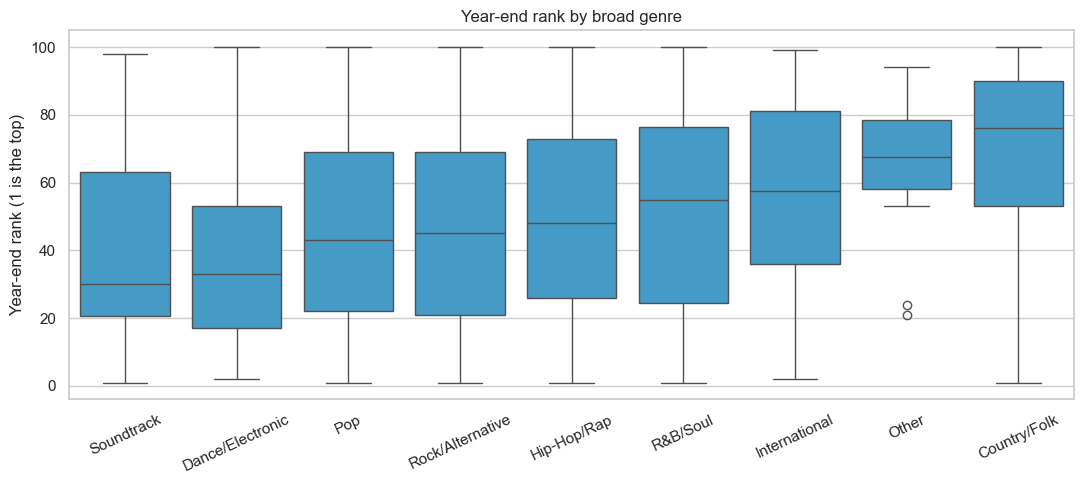

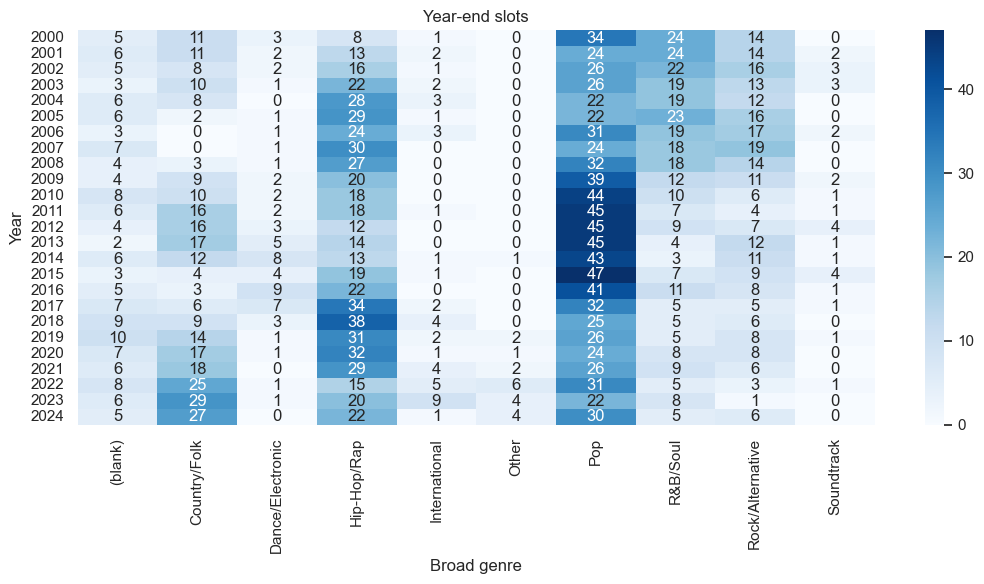

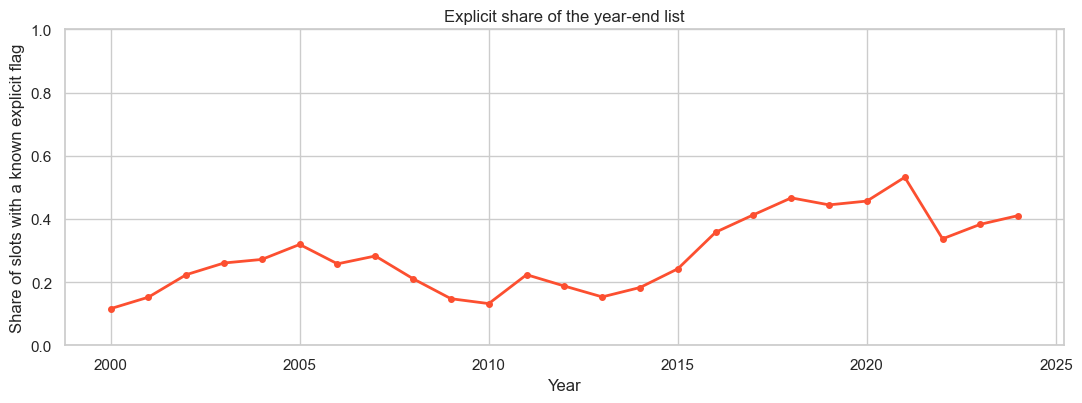

year
2000    0.116
2001    0.152
2002    0.223
2003     0.26
2004    0.272
2005    0.319
2006    0.258
2007    0.283
2008    0.211
2009    0.147
2010    0.132
2011    0.223
2012    0.188
2013    0.153
2014    0.183
2015    0.242
2016    0.358
2017    0.413
2018    0.467
2019    0.444
2020    0.457
2021    0.532
2022    0.337
2023    0.383
2024    0.411
Median rank, explicit: 47.0
Median rank, clean: 52.0


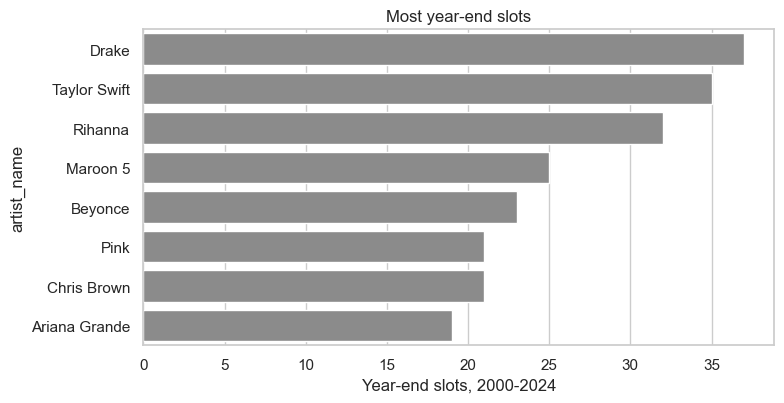

In [4]:
known_genre = slot.dropna(subset=["broad_genre"]).copy()
rank_by_genre = (
    known_genre.groupby("broad_genre")["rank"]
    .agg(["count", "median"])
    .sort_values("median")
)
display(rank_by_genre.style.format({"median": "{:.1f}"}).background_gradient(subset=["median"], cmap="Blues"))

fig, ax = plt.subplots(figsize=(11, 5))
order = rank_by_genre.index.tolist()
sns.boxplot(data=known_genre, x="broad_genre", y="rank", order=order, ax=ax, color=PALETTE[0])
ax.set_xlabel("")
ax.set_ylabel("Year-end rank (1 is the top)")
ax.set_title("Year-end rank by broad genre")
ax.tick_params(axis="x", rotation=25)
fig.tight_layout()
plt.show()

mix = pd.crosstab(slot.year, slot.broad_genre.fillna("(blank)"))
fig, ax = plt.subplots(figsize=(11, 6))
sns.heatmap(mix, annot=True, fmt="d", cmap="Blues", ax=ax)
ax.set_xlabel("Broad genre")
ax.set_ylabel("Year")
ax.set_title("Year-end slots")
fig.tight_layout()
plt.show()

known_explicit = slot.dropna(subset=["is_explicit"]).copy()
explicit_share = known_explicit.groupby("year").is_explicit.mean()
fig, ax = plt.subplots(figsize=(11, 4.2))
ax.plot(explicit_share.index, explicit_share.values, color=PALETTE[1], lw=2, marker="o", ms=4)
ax.set_ylim(0, 1)
ax.set_xlabel("Year")
ax.set_ylabel("Share of slots with a known explicit flag")
ax.set_title("Explicit share of the year-end list")
fig.tight_layout()
plt.show()
print(explicit_share.round(3).to_string())
explicit_flag = known_explicit.is_explicit.astype(str).eq("True")
print("Median rank, explicit:", known_explicit.loc[explicit_flag, "rank"].median())
print("Median rank, clean:", known_explicit.loc[~explicit_flag, "rank"].median())

top_artists = chart.artist_name.value_counts().head(8)
fig, ax = plt.subplots(figsize=(8, 4.2))
sns.barplot(x=top_artists.values, y=top_artists.index, ax=ax, color=PALETTE[4])
ax.set_xlabel("Year-end slots, 2000-2024")
ax.set_title("Most year-end slots")
fig.tight_layout()
plt.show()

**Interpretation:** <br>
A lower median rank is a better typical position. Soundtrack's median is 30 on 28 slots. Among the larger genres, Dance/Electronic sits at median rank 33 (61 slots), Pop at 43, Rock/Alternative at 45, and Hip-Hop/Rap at 48. Country/Folk sits at 76 across 285 slots. The heatmap is the mix: Hip-Hop/Rap and Pop take more of the list in the later years, and Country/Folk remains a block of lower ranks.

The explicit share, computed only where the flag is known, is about 12% in 2000 and 53% in 2021, the peak year. Explicit slots have a median rank of 47, clean slots 52. Drake has 37 year-end slots, Taylor Swift 35, Rihanna 32.

# **5. Audio, Words, and Rank:** <a id="Audio"></a>

Chart slots with audio features: 2133


,feature,spearman_with_rank,p
0,danceability,-0.096,8.496e-06
2,valence,-0.066,2.359e-03
4,speechiness,-0.065,2.521e-03
5,loudness,-0.009,6.661e-01
7,duration_ms,-0.007,7.514e-01
1,energy,0.003,8.892e-01
6,tempo,0.011,6.149e-01
3,acousticness,0.014,5.270e-01
8,lexical_diversity,0.089,3.803e-05


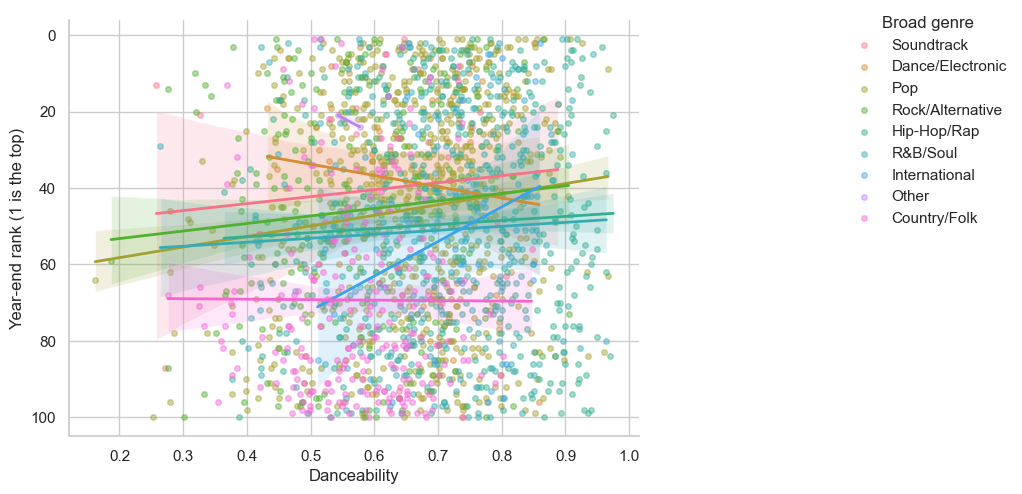

Slots with a primary topic: 2483 of 2484


,count,median
topic,,
love_relationships,630,51.5
heartbreak_loss,428,49.0
sex_desire,384,49.0
lifestyle_success,288,52.0
empowerment_confidence,262,46.0
party_celebration,223,50.0
self_reflection_growth,185,54.0
social_commentary,46,53.0
faith_spirituality,19,43.0


Emotion Spearman with rank:
  anger             -0.038  p=6.042e-02
  anticipation      -0.005  p=8.221e-01
  disgust           -0.024  p=2.245e-01
  fear              -0.018  p=3.730e-01
  joy               -0.037  p=6.726e-02
  negative          -0.049  p=1.512e-02
  positive          -0.038  p=5.965e-02
  sadness           -0.036  p=7.413e-02
  surprise          -0.025  p=2.057e-01
  trust             -0.031  p=1.226e-01


In [5]:
audio = slot.dropna(subset=["danceability", "energy", "valence", "loudness", "tempo"]).copy()
print("Chart slots with audio features:", len(audio))
feature_cols = [
    "danceability", "energy", "valence", "acousticness", "speechiness",
    "loudness", "tempo", "duration_ms", "lexical_diversity",
]
rows = []
for col in feature_cols:
    rho, p = stats.spearmanr(audio["rank"], audio[col])
    rows.append({"feature": col, "spearman_with_rank": rho, "p": p})
assoc = pd.DataFrame(rows).sort_values("spearman_with_rank")
display(assoc.style.format({"spearman_with_rank": "{:.3f}", "p": "{:.3e}"}).background_gradient(subset=["spearman_with_rank"], cmap="RdBu_r"))

g = sns.lmplot(
    data=audio.dropna(subset=["broad_genre"]),
    x="danceability",
    y="rank",
    hue="broad_genre",
    hue_order=rank_by_genre.index.tolist(),
    height=5,
    aspect=1.35,
    scatter_kws={"s": 16, "alpha": 0.45},
    line_kws={"lw": 2},
)
sns.move_legend(g, "upper left", bbox_to_anchor=(1.02, 1), title="Broad genre", frameon=False)
g.set_axis_labels("Danceability", "Year-end rank (1 is the top)")
g.ax.invert_yaxis()
plt.show()

prim = topics.loc[topics.is_primary.eq(True)].copy()
assert prim.duplicated(["title", "artist_name"]).sum() == 0
slot_topic = chart.merge(prim, on=["title", "artist_name"], how="left")
print("Slots with a primary topic:", int(slot_topic.topic.notna().sum()), "of", len(slot_topic))
topic_rank = (
    slot_topic.dropna(subset=["topic"])
    .groupby("topic")["rank"]
    .agg(["count", "median"])
    .sort_values("count", ascending=False)
)
display(topic_rank.style.format({"median": "{:.1f}"}).background_gradient(subset=["median"], cmap="Blues"))

emo_cols = [
    "anger", "anticipation", "disgust", "fear", "joy",
    "negative", "positive", "sadness", "surprise", "trust",
]
slot_emo = slot.merge(emotions, on=["title", "artist_name"], how="left")
print("Emotion Spearman with rank:")
for col in emo_cols:
    rho, p = stats.spearmanr(slot_emo["rank"], slot_emo[col])
    print(f"  {col:16s} {rho:7.3f}  p={p:.3e}")

**Interpretation:** <br>
Danceability is the strongest audio association, and it is still small: Spearman −0.096, so a more danceable slot leans slightly toward a better rank. Valence and speechiness are weaker in the same direction. Energy, loudness, tempo, acousticness, and duration are flat. Lexical diversity leans the other way (Spearman 0.089): a slightly more varied lyric sits a little lower on the list. The scatter inverts the rank axis so the top of the chart is at the top of the figure; the genre lines are nearly parallel.

Primary-topic median ranks, for every topic with a real count, sit between the mid-40s and the mid-50s. One chart slot has no primary topic and stays that way. Every emotion-count Spearman with rank is inside ±0.05.

# **6. What Lines Up with Year-End Rank:** <a id="Model"></a>

In [6]:
use = slot.dropna(subset=["danceability", "energy", "valence", "broad_genre"]).copy()
print("Complete chart slots in the model:", len(use))
assert len(use) == 2043
y = use["rank"]
X = use[["danceability", "energy", "valence", "broad_genre"]]
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.25, random_state=7)
audio_model = LinearRegression().fit(Xtr[["danceability", "energy", "valence"]], ytr)
audio_hat = audio_model.predict(Xte[["danceability", "energy", "valence"]])
print("Hold-out R2, rank ~ danceability + energy + valence:", round(r2_score(yte, audio_hat), 3))

pipe = Pipeline([
    ("pre", ColumnTransformer([
        ("num", "passthrough", ["danceability", "energy", "valence"]),
        ("cat", OneHotEncoder(drop="first"), ["broad_genre"]),
    ])),
    ("lr", LinearRegression()),
])
pipe.fit(Xtr, ytr)
print("Hold-out R2, rank ~ audio + broad genre:", round(r2_score(yte, pipe.predict(Xte)), 3))
print("Reference genre (dropped level):", sorted(use.broad_genre.unique())[0])
names = pipe.named_steps["pre"].get_feature_names_out()
coef = pd.Series(pipe.named_steps["lr"].coef_, index=names).sort_values()
display(coef.round(2).to_frame("coefficient").style.background_gradient(cmap="RdBu_r"))

Complete chart slots in the model: 2043
Hold-out R2, rank ~ danceability + energy + valence: -0.003
Hold-out R2, rank ~ audio + broad genre: 0.092
Reference genre (dropped level): Country/Folk


,coefficient
cat__broad_genre_Other,-44.450000
cat__broad_genre_Soundtrack,-29.880000
cat__broad_genre_Dance/Electronic,-27.370000
cat__broad_genre_Pop,-21.500000
cat__broad_genre_Rock/Alternative,-21.230000
num__danceability,-17.140000
cat__broad_genre_Hip-Hop/Rap,-15.900000
cat__broad_genre_International,-13.890000
cat__broad_genre_R&B/Soul,-13.710000
num__valence,-6.280000


**Interpretation:** <br>
Audio features alone have a hold-out R² of −0.003: danceability, energy, and valence do not place the year-end rank. Adding broad genre reaches 0.092. The dropped genre is Country/Folk, the group with the weakest median rank, so the other genre coefficients are shifts from that baseline toward a better (more negative) rank. 320 tracks with blank audio, and the slots that inherit them, stay out of the fit. A repeated song contributes one row per year it charted, because the question is about slots.

# **7. What It Means — Working Synthesis:** <a id="Synthesis"></a> <br>
The year-end list here is 2,484 slots and 2,246 songs, from 2000 through 2024, with 16 ranks absent and left absent. Genre shifts the typical slot: Dance/Electronic median rank 33, Pop 43, Hip-Hop/Rap 48, Country/Folk 76. That shift is most of what a linear model can hold (hold-out R² 0.092 once genre is added, and −0.003 on audio features alone).

Danceability's rank correlation is −0.096. Energy, tempo, loudness, and duration are flat. Explicit slots and clean slots differ by a few rank places at the median (47 vs 52), while the explicit share of the list rises from about 12% in 2000 to 53% in 2021. Lyric topic and emotion counts do not separate the list. Drake, Taylor Swift, and Rihanna lead the slot counts, and 231 songs return for another year.

**Open follow-ups:** <br>
- Weekly Hot 100 history would show how a year-end rank was earned. This file starts at the year-end list.
- The n-gram table can answer wording questions once the question is about phrases rather than the slot.